# TEXTSENSE — ĐỒ ÁN KHOA HỌC DỮ LIỆU

**Notebook thực hành theo 4 câu của đề.** Mỗi bước có một cell nhỏ, kết quả bảng và biểu đồ hiện ngay bên dưới khi chạy. Chạy lần lượt từ trên xuống. Dữ liệu sử dụng: **Twitter và Reddit**.

**Nhãn quy ước:** -1 → 1 (Phản cảm); 0 và +1 → 0 (Không phản cảm). Đây là **nhãn suy ra từ cảm xúc**, không phải nhãn phản cảm do con người xác nhận.

## CÂU 1 — THU THẬP, PHÂN TÍCH VÀ THỐNG KÊ MÔ TẢ (2,0 ĐIỂM)

**1.1. Khai báo thư viện**

In [1]:
# Nhập các thư viện cần dùng; không tự chạy quá trình train.
import argparse
import hashlib
import json
import platform
import re
import unicodedata
import tempfile
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import Iterable

import joblib
from joblib import Memory
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_recall_fscore_support)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

**1.2. Khai báo dữ liệu và quy ước nhãn**

In [2]:
# Xác định data, outputs và ánh xạ nhãn -1/0/1 sang 1/0.
ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'Twitter_Data.csv').exists():
    ROOT = ROOT / '01_TRAIN_MODEL'
if not (ROOT / 'data' / 'Twitter_Data.csv').exists():
    raise FileNotFoundError('Mở notebook ở thư mục 01_TRAIN_MODEL hoặc TextSense (thư mục gốc).')
DATA = ROOT / 'data'
OUTPUT = ROOT / 'outputs'
SEED = 42
# These are proxy labels derived from sentiment, NOT ground-truth racism/sexism labels.
BINARY_MAPPING = {-1: 1, 0: 0, 1: 0}
BINARY_NAMES = {0: 'Không phản cảm', 1: 'Phản cảm'}
DEFAULT_C_VALUES = (0.5, 1.0, 2.0, 5.0)
DATASET_URL = 'https://www.kaggle.com/datasets/cosmos98/twitter-and-reddit-sentimental-analysis-dataset'
DATASET_LICENSE = 'CC BY-NC-SA 4.0 (as displayed on the Kaggle dataset page; verify terms before redistribution)'


RETWEET_PREFIX_RE = re.compile(r'^\s*rt\s+@[\w_]+\s*:?[ \t]*', flags=re.I)
URL_RE = re.compile(r'(?:https?://|www\.)\S+', flags=re.I)

In [3]:
# Chuẩn hóa text để thống kê và dự đoán thống nhất.
def normalize_text(value) -> str:
    """Apply the same normalization to pre-cleaned training text and raw web input.

    Kaggle files contain pre-cleaned text (lowercase with punctuation removed). Mirror
    that representation at inference: NFKC, remove leading RT @handle, remove URLs,
    casefold, remove punctuation and collapse whitespace. Accented letters are kept.
    """
    if pd.isna(value):
        return ''
    value = unicodedata.normalize('NFKC', str(value))
    value = RETWEET_PREFIX_RE.sub(' ', value)
    value = URL_RE.sub(' ', value)
    value = value.casefold()
    value = re.sub(r'[^\w\s]', '', value, flags=re.UNICODE)
    value = value.replace('_', ' ')
    return ' '.join(value.split())


In [4]:
# Tạo khóa phát hiện văn bản trùng.
def token_key(value) -> str:
    """Canonical token key used for deduplication and split-leakage checks."""
    value = unicodedata.normalize('NFKC', normalize_text(value)).casefold()
    tokens = re.findall(r'\w+', value, flags=re.UNICODE)
    return ' '.join(tokens)


In [5]:
# Tính mã kiểm tra nguồn CSV.
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b''):
            digest.update(chunk)
    return digest.hexdigest()


In [6]:
# Tính mã kiểm tra dữ liệu sau xử lý.
def sha256_frame(frame: pd.DataFrame, columns: Iterable[str]) -> str:
    stable = frame[list(columns)].copy()
    sort_cols = [c for c in ('dedup_key', 'category', 'label', 'source', 'text') if c in stable]
    if sort_cols:
        stable = stable.sort_values(sort_cols, kind='mergesort').reset_index(drop=True)
    payload = stable.to_csv(index=False, lineterminator='\n').encode('utf-8')
    return hashlib.sha256(payload).hexdigest()


In [7]:
# Đọc cả Twitter_Data.csv và Reddit_Data.csv.
def read_sources(data_dir: Path = DATA) -> tuple[pd.DataFrame, dict]:
    data_dir = Path(data_dir)
    items, source_hashes = [], {}
    for filename, col in [('Twitter_Data.csv', 'clean_text'), ('Reddit_Data.csv', 'clean_comment')]:
        path = data_dir / filename
        if not path.is_file():
            raise FileNotFoundError(f'Missing data file: {path}. Copy both CSV files into the data folder.')
        source_hashes[filename] = sha256_file(path)
        frame = pd.read_csv(path, dtype={col: 'string'}, low_memory=False)
        missing = {col, 'category'} - set(frame.columns)
        if missing:
            raise ValueError(f'{filename} missing required columns: {sorted(missing)}')
        part = frame[[col, 'category']].rename(columns={col: 'text'}).copy()
        part['source'] = filename
        items.append(part)
    return pd.concat(items, ignore_index=True), source_hashes


In [8]:
# Loại dòng không hợp lệ / trùng để dùng chung tập dữ liệu.
def clean_sentiment(data_dir: Path = DATA) -> tuple[pd.DataFrame, dict]:
    df, source_hashes = read_sources(data_dir)
    raw_category = pd.to_numeric(df['category'], errors='coerce')
    stats = {
        'raw_rows': int(len(df)),
        'raw_source_counts': {str(k): int(v) for k, v in df['source'].value_counts().items()},
        'raw_category_counts': {str(int(k)): int(v) for k, v in raw_category.value_counts().sort_index().items() if pd.notna(k)},
        'raw_source_category_counts': {
            str(source): {str(int(k)): int(v) for k, v in values.items() if pd.notna(k)}
            for source, group in df.assign(_category_num=raw_category).groupby('source')
            for values in [group['_category_num'].value_counts().sort_index()]
        },
        'source_file_sha256': source_hashes
    }
    df = df.dropna(subset=['text', 'category']).copy()
    stats['retweet_prefix_rows_normalized'] = int(df['text'].astype(str).str.match(RETWEET_PREFIX_RE).sum())
    df['text'] = df['text'].map(normalize_text)
    df['category'] = pd.to_numeric(df['category'], errors='coerce')
    df = df.loc[df['text'].str.len().ge(3) & df['category'].isin([-1, 0, 1])].copy()
    df['category'] = df['category'].astype('int64')
    stats['valid_before_dedup'] = int(len(df))
    df['dedup_key'] = df['text'].map(token_key)
    df = df.loc[df['dedup_key'].str.len().gt(0)].copy()
    conflicts = df.groupby('dedup_key')['category'].nunique()
    conflicting_keys = set(conflicts[conflicts > 1].index)
    stats['conflicting_token_groups_removed'] = int(len(conflicting_keys))
    df = df.loc[~df['dedup_key'].isin(conflicting_keys)].copy()
    before = len(df)
    df = df.drop_duplicates('dedup_key', keep='first').reset_index(drop=True)
    stats['duplicate_token_rows_removed'] = int(before - len(df))
    stats['unique_trainable_rows'] = int(len(df))
    stats['counts'] = {str(int(k)): int(v) for k, v in df['category'].value_counts().sort_index().items()}
    stats['source_counts'] = {str(k): int(v) for k, v in df['source'].value_counts().items()}
    stats['clean_source_category_counts'] = {
        str(source): {str(int(k)): int(v) for k, v in group['category'].value_counts().sort_index().items()}
        for source, group in df.groupby('source')
    }
    stats['canonical_dataset_sha256'] = sha256_frame(df, ['dedup_key', 'category', 'source'])
    return df, stats


**1.3. Đọc dữ liệu từ hai nguồn và xem 5 dòng đầu**

In [9]:
# Nạp cả hai CSV, làm sạch, thêm nhãn 0/1 và xem các dòng đầu.
from IPython.display import display
assert (DATA / 'Twitter_Data.csv').is_file() and (DATA / 'Reddit_Data.csv').is_file()
clean_df, source_stats = clean_sentiment(DATA)
clean_df['label'] = clean_df['category'].map(BINARY_MAPPING).astype(int)
assert {'Twitter_Data.csv', 'Reddit_Data.csv'} == set(clean_df['source'])
print('Số dòng ban đầu theo nguồn:', source_stats['raw_source_counts'])
print('Số mẫu sau làm sạch / loại trùng:', len(clean_df))
display(clean_df[['source', 'text', 'category', 'label']].head(5))

Số dòng ban đầu theo nguồn: {'Twitter_Data.csv': 162980, 'Reddit_Data.csv': 37249}
Số mẫu sau làm sạch / loại trùng: 196056


,source,text,category,label
0,Twitter_Data.csv,when modi promised minimum government maximum ...,-1,1
1,Twitter_Data.csv,talk all the nonsense and continue all the dra...,0,0
2,Twitter_Data.csv,what did just say vote for modi welcome bjp to...,1,0
3,Twitter_Data.csv,asking his supporters prefix chowkidar their n...,1,0
4,Twitter_Data.csv,answer who among these the most powerful world...,1,0


**1.4. Thống kê nguồn và phân bố nhãn**

In [10]:
# Đếm số mẫu theo nguồn, nhãn gốc và tỷ lệ nhãn mới.
display(pd.crosstab(clean_df['source'], clean_df['category'], margins=True))
display(pd.crosstab(clean_df['source'], clean_df['label'], margins=True))
print('Tỷ lệ phần trăm nhãn nhị phân:')
display((clean_df['label'].value_counts(normalize=True).sort_index() * 100).round(2))

category,-1,0,1,All
source,,,,
Reddit_Data.csv,8227,12562,15679,36468
Twitter_Data.csv,34920,53677,70991,159588
All,43147,66239,86670,196056


label,0,1,All
source,,,
Reddit_Data.csv,28241,8227,36468
Twitter_Data.csv,124668,34920,159588
All,152909,43147,196056


Tỷ lệ phần trăm nhãn nhị phân:


label
0    77.99
1    22.01
Name: proportion, dtype: float64

In [11]:
# Xuất thống kê mô tả theo từng nguồn.
def save_data_summary(df: pd.DataFrame, out: Path) -> pd.DataFrame:
    """Save descriptive counts for the two source datasets and proxy labels."""
    summary = (df.groupby(['source', 'category', 'label'], observed=True)
                 .size().rename('samples').reset_index())
    original_names = {-1: 'Tiêu cực', 0: 'Trung tính', 1: 'Tích cực'}
    summary['original_sentiment'] = summary['category'].map(original_names)
    summary['binary_name'] = summary['label'].map(BINARY_NAMES)
    source_totals = summary.groupby('source')['samples'].transform('sum')
    summary['percent_within_source'] = (summary['samples'] / source_totals * 100).round(3)
    summary['percent_overall'] = (summary['samples'] / summary['samples'].sum() * 100).round(3)
    summary = summary[['source', 'category', 'original_sentiment', 'label', 'binary_name',
                       'samples', 'percent_within_source', 'percent_overall']]
    out.mkdir(parents=True, exist_ok=True)
    summary.to_csv(out / 'binary_data_summary.csv', index=False, encoding='utf-8-sig')
    return summary


In [12]:
# Vẽ 5 biểu đồ nguồn, nhãn gốc, nhãn nhị phân, độ dài, Top 20 từ.
def save_descriptive_outputs(df: pd.DataFrame, out: Path) -> dict:
    """Create compact descriptive tables/charts from the cleaned combined dataset."""
    out.mkdir(parents=True, exist_ok=True)
    lengths = df['text'].fillna('').astype(str).str.split().str.len()
    stopwords = {
        'the','and','for','you','your','are','was','were','with','this','that','have','has',
        'had','but','not','from','they','them','their','there','here','what','when','where',
        'who','how','why','will','would','could','should','can','all','any','our','out','about',
        'just','than','then','into','its','his','her','she','him','he','his','one','two','get',
        'got','like','im','ive','dont','doesnt','didnt','amp','rt','www','com'
    }
    tokens = Counter()
    for text in df['text'].fillna('').astype(str):
        tokens.update(t for t in re.findall(r"[a-z0-9']+", text.lower())
                      if len(t) > 2 and t not in stopwords)
    top_terms = tokens.most_common(20)
    pd.DataFrame(top_terms, columns=['term', 'frequency']).to_csv(
        out / 'binary_top20_terms.csv', index=False, encoding='utf-8-sig')

    stats = {
        'total_clean_unique_rows': int(len(df)),
        'rows_by_source': {str(k): int(v) for k, v in df['source'].value_counts().items()},
        'original_label_counts': {str(int(k)): int(v) for k, v in df['category'].value_counts().sort_index().items()},
        'binary_label_counts': {str(int(k)): int(v) for k, v in df['label'].value_counts().sort_index().items()},
        'text_length_words': {
            'mean': float(lengths.mean()), 'median': float(lengths.median()),
            'q1': float(lengths.quantile(.25)), 'q3': float(lengths.quantile(.75)),
            'min': int(lengths.min()), 'max': int(lengths.max())
        },
        'top_20_terms': [{'term': t, 'frequency': int(n)} for t, n in top_terms],
        'note': 'Thống kê mô tả từ dữ liệu đã làm sạch và loại trùng, trước khi chia tập.'
    }
    (out / 'binary_descriptive_stats.json').write_text(
        json.dumps(stats, ensure_ascii=False, indent=2), encoding='utf-8')

    try:
        import matplotlib
        matplotlib.use('Agg')
        import matplotlib.pyplot as plt

        source_counts = df['source'].value_counts().reindex(
            ['Twitter_Data.csv', 'Reddit_Data.csv'], fill_value=0)
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.bar(['Twitter', 'Reddit'], source_counts.values)
        ax.set(title='Số lượng văn bản theo nguồn', ylabel='Số mẫu')
        ax.grid(axis='y', alpha=.25)
        fig.tight_layout(); fig.savefig(out / 'binary_source_distribution.png', dpi=160); plt.close(fig)

        original_counts = df['category'].value_counts().reindex([-1, 0, 1], fill_value=0)
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.bar(['Tiêu cực (-1)', 'Trung tính (0)', 'Tích cực (1)'], original_counts.values)
        ax.set(title='Phân bố nhãn cảm xúc gốc', ylabel='Số mẫu')
        ax.grid(axis='y', alpha=.25)
        fig.tight_layout(); fig.savefig(out / 'binary_original_label_distribution.png', dpi=160); plt.close(fig)

        binary_counts = df['label'].value_counts().reindex([0, 1], fill_value=0)
        fig, ax = plt.subplots(figsize=(6, 4.5))
        ax.bar(['0 - Không phản cảm', '1 - Phản cảm'], binary_counts.values)
        ax.set(title='Phân bố nhãn nhị phân proxy', ylabel='Số mẫu')
        ax.grid(axis='y', alpha=.25)
        fig.tight_layout(); fig.savefig(out / 'binary_label_distribution.png', dpi=160); plt.close(fig)

        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.hist(lengths.clip(upper=100), bins=30)
        ax.set(title='Phân bố độ dài văn bản (giới hạn hiển thị 100 từ)',
               xlabel='Số từ trong văn bản', ylabel='Số mẫu')
        ax.grid(axis='y', alpha=.25)
        fig.tight_layout(); fig.savefig(out / 'binary_text_length_distribution.png', dpi=160); plt.close(fig)

        if top_terms:
            terms, frequencies = zip(*top_terms)
            fig, ax = plt.subplots(figsize=(9, 6))
            ax.barh(list(terms)[::-1], list(frequencies)[::-1])
            ax.set(title='20 từ phổ biến nhất sau khi loại từ dừng', xlabel='Tần suất')
            ax.grid(axis='x', alpha=.25)
            fig.tight_layout(); fig.savefig(out / 'binary_top20_terms.png', dpi=160); plt.close(fig)
    except ImportError:
        stats['chart_warning'] = 'Không tạo được biểu đồ vì thiếu matplotlib; cài requirements.txt để bổ sung.'
        (out / 'binary_descriptive_stats.json').write_text(
            json.dumps(stats, ensure_ascii=False, indent=2), encoding='utf-8')
    return stats


**1.5. Tạo và HIỂN THỊ biểu đồ trực tiếp trong notebook**

In [13]:
# Lưu bảng và biểu đồ bằng dữ liệu đã làm sạch.
OUTPUT.mkdir(parents=True, exist_ok=True)
summary_df = save_data_summary(clean_df, OUTPUT)
descriptive_stats = save_descriptive_outputs(clean_df, OUTPUT)
print('Đã tạo bảng mô tả và 5 biểu đồ tại:', OUTPUT)
display(summary_df.head(6))

Đã tạo bảng mô tả và 5 biểu đồ tại: C:\Users\vothi\OneDrive\Desktop\TextSense\01_TRAIN_MODEL\outputs


,source,category,original_sentiment,label,binary_name,samples,percent_within_source,percent_overall
0,Reddit_Data.csv,-1,Tiêu cực,1,Phản cảm,8227,22.560,4.196
1,Reddit_Data.csv,0,Trung tính,0,Không phản cảm,12562,34.447,6.407
2,Reddit_Data.csv,1,Tích cực,0,Không phản cảm,15679,42.994,7.997
3,Twitter_Data.csv,-1,Tiêu cực,1,Phản cảm,34920,21.881,17.811
4,Twitter_Data.csv,0,Trung tính,0,Không phản cảm,53677,33.635,27.378
5,Twitter_Data.csv,1,Tích cực,0,Không phản cảm,70991,44.484,36.210


BIỂU ĐỒ: Số mẫu Twitter và Reddit


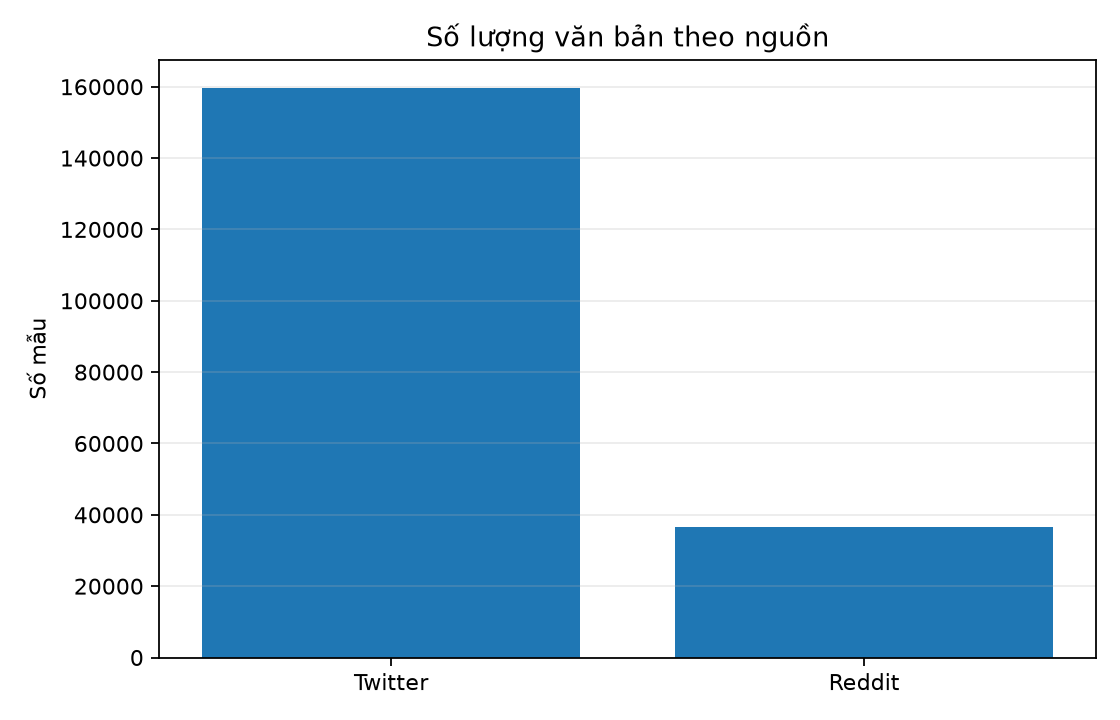

BIỂU ĐỒ: Phân bố 3 nhãn cảm xúc gốc


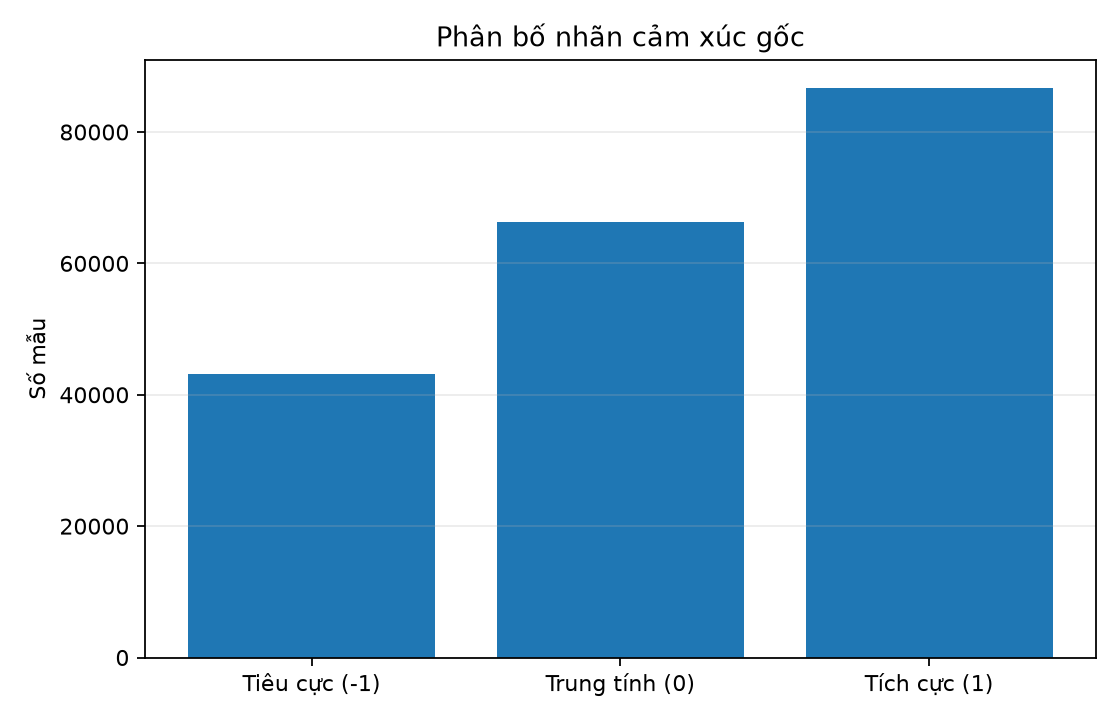

BIỂU ĐỒ: Phân bố 2 nhãn sau ánh xạ


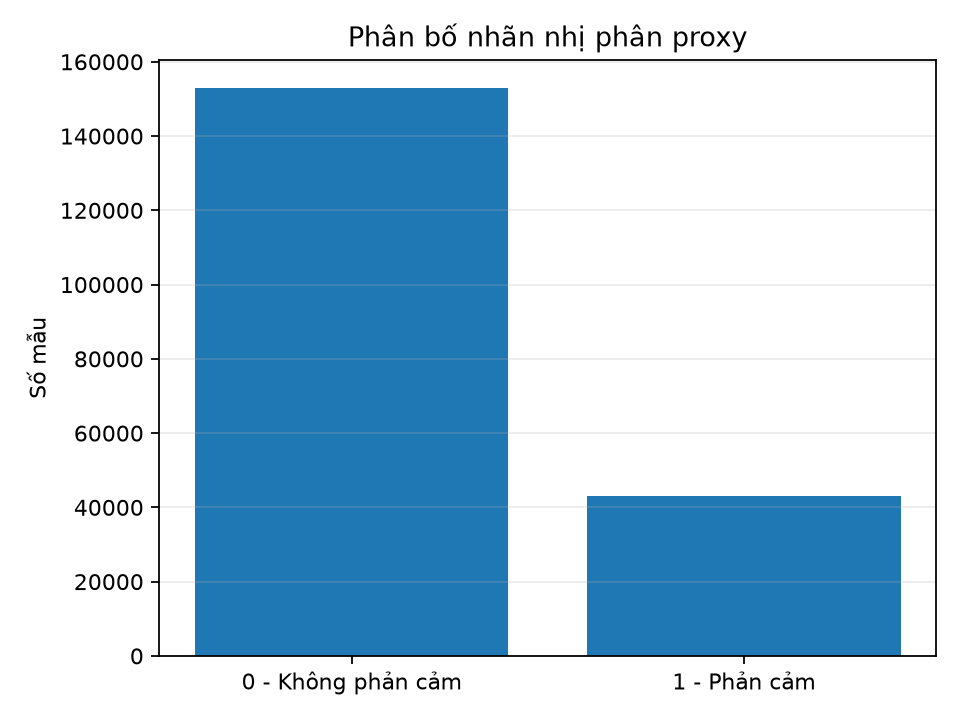

BIỂU ĐỒ: Độ dài văn bản


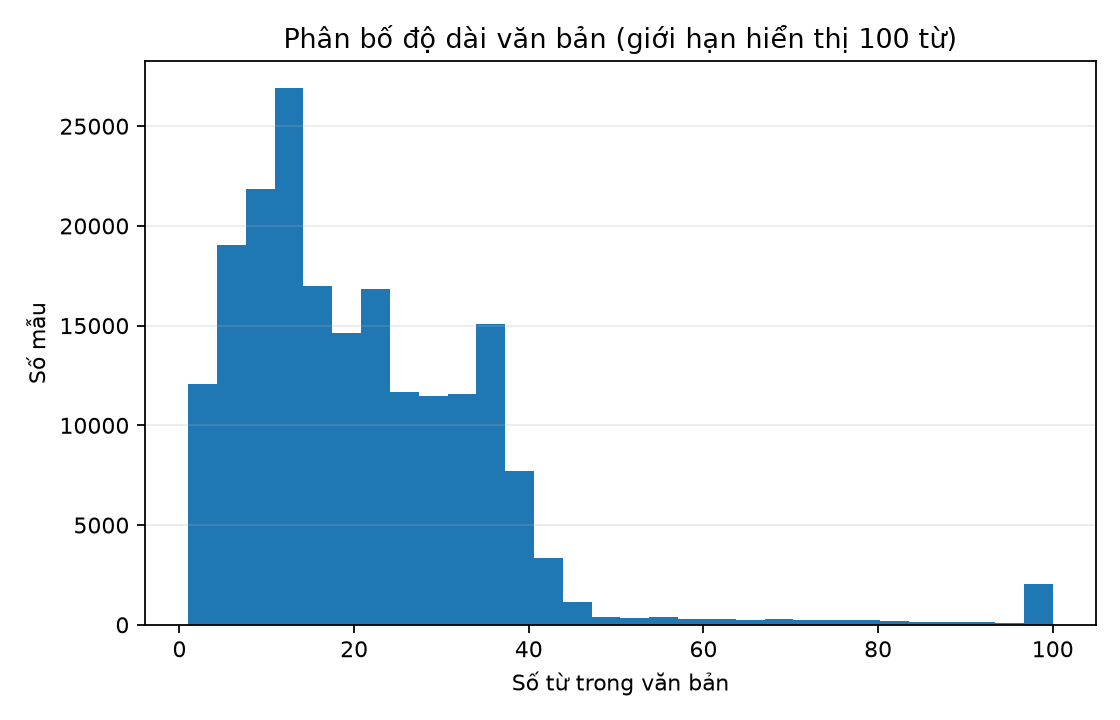

BIỂU ĐỒ: Top 20 từ phổ biến


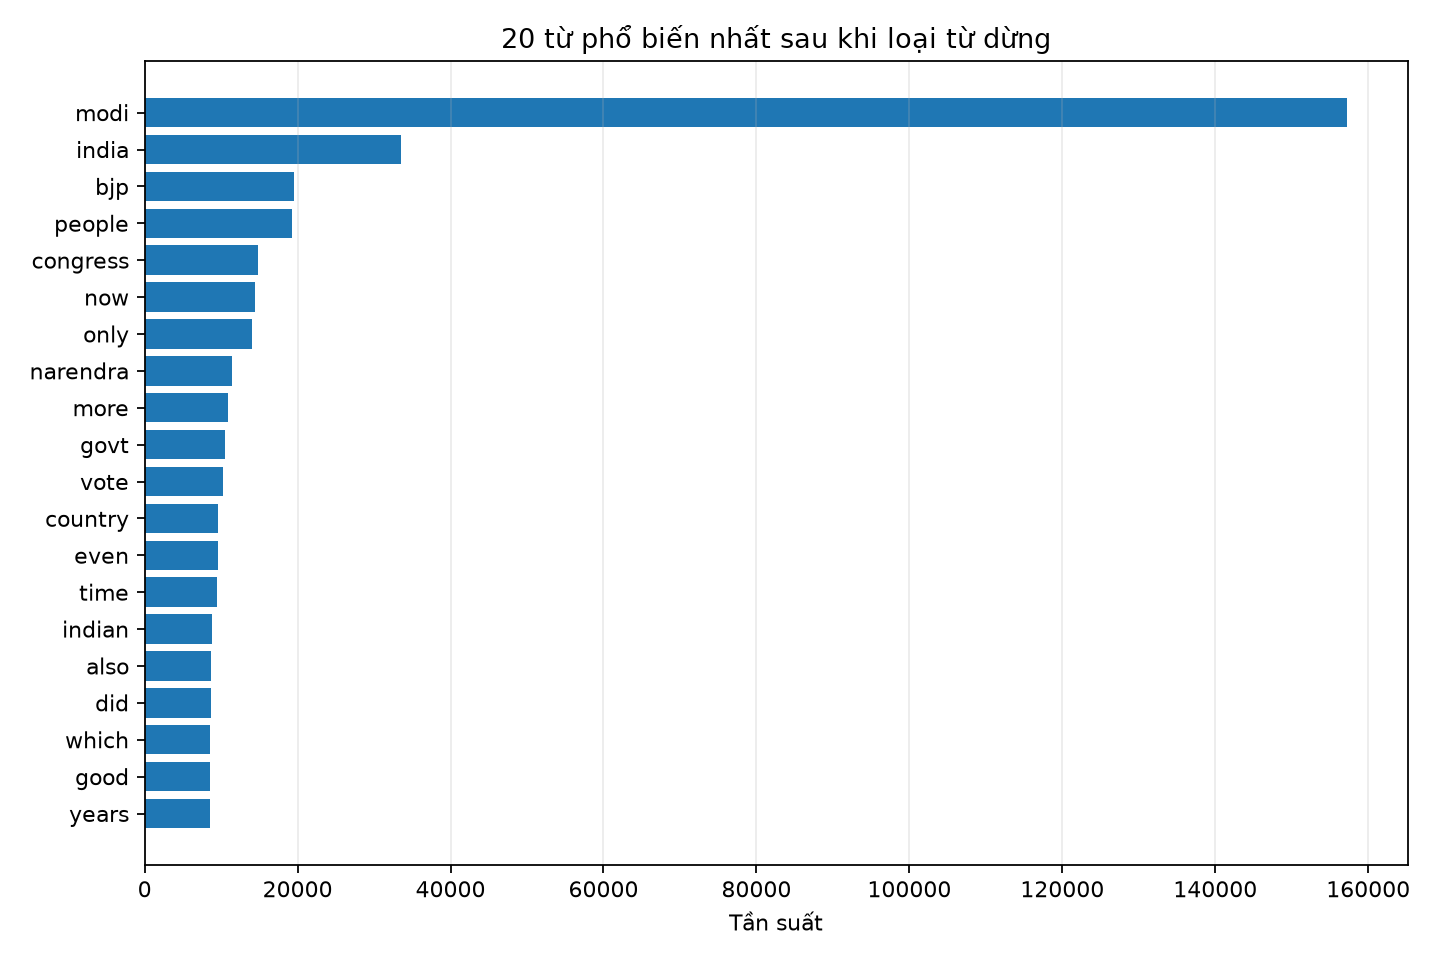

Thống kê số từ: {'mean': 21.88878177663525, 'median': 18.0, 'q1': 10.0, 'q3': 29.0, 'min': 1, 'max': 1307}


,term,frequency
0,modi,157280
1,india,33564
2,bjp,19494
3,people,19224
4,congress,14826
5,now,14378
6,only,14065
7,narendra,11374
8,more,10958
9,govt,10470


In [14]:
# Hiển thị rõ từng hình ngay dưới cell, đồng thời vẫn lưu PNG trong outputs/.
from IPython.display import Image, display
for title, name in [
    ('Số mẫu Twitter và Reddit', 'binary_source_distribution.png'),
    ('Phân bố 3 nhãn cảm xúc gốc', 'binary_original_label_distribution.png'),
    ('Phân bố 2 nhãn sau ánh xạ', 'binary_label_distribution.png'),
    ('Độ dài văn bản', 'binary_text_length_distribution.png'),
    ('Top 20 từ phổ biến', 'binary_top20_terms.png'),
]:
    print('BIỂU ĐỒ:', title)
    display(Image(filename=str(OUTPUT / name)))
print('Thống kê số từ:', descriptive_stats['text_length_words'])
display(pd.read_csv(OUTPUT / 'binary_top20_terms.csv').head(20))

**1.6. Top 15 từ ngữ có thể mang sắc thái xúc phạm / thô tục**

Đếm **số lần xuất hiện** và **số bình luận chứa từ** từ danh sách đối chiếu tiếng Anh, trên toàn bộ dữ liệu sạch và riêng nhóm nhãn proxy 1. Thống kê này **không** xác minh nội dung xúc phạm và không phải bộ gán nhãn hate speech. Bảng và biểu đồ được hiển thị trực tiếp, đồng thời xuất CSV/PNG trong `outputs/`.


In [15]:
# Top 15 tu ngu co the xuc pham / tho tuc (danh sach kiem tra co gioi han).
# Luu y: nhan 1 la proxy tu cam xuc tieu cuc, khong phai nhan phan cam da kiem chung.
SUSPECT_TERMS_EN = frozenset({
    'abusive', 'asshole', 'assholes', 'bastard', 'bastards', 'bitch', 'bitches',
    'bullshit', 'crap', 'crappy', 'damn', 'dick', 'dicks', 'dumb',
    'dumbass', 'fool', 'fools', 'fuck', 'fucked', 'fucker', 'fuckers',
    'fucking', 'fucks', 'idiot', 'idiots', 'jerk', 'jerks', 'loser',
    'losers', 'moron', 'morons', 'pathetic', 'scum', 'shit', 'shitty',
    'stfu', 'stupid', 'suck', 'sucks', 'trash', 'ugly', 'worthless',
    'wtf',
})

def suspect_term_frequency(frame: pd.DataFrame, limit: int = 15) -> pd.DataFrame:
    """Count occurrences and documents for each lexicon-matched English token."""
    occurrences, documents = Counter(), Counter()
    for text in frame['text'].fillna('').astype(str):
        tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text.casefold())
        found = [term for term in tokens if term in SUSPECT_TERMS_EN]
        occurrences.update(found)
        documents.update(set(found))
    rows = [{'tu_ngu': term, 'so_lan_xuat_hien': count,
             'so_binh_luan_chua_tu': documents[term]}
            for term, count in sorted(occurrences.items(), key=lambda item: (-item[1], item[0]))[:limit]]
    return pd.DataFrame(rows, columns=['tu_ngu', 'so_lan_xuat_hien', 'so_binh_luan_chua_tu'])

suspect_all = suspect_term_frequency(clean_df)
suspect_proxy1 = suspect_term_frequency(clean_df.loc[clean_df['label'].eq(1)])
OUTPUT.mkdir(parents=True, exist_ok=True)
suspect_all.to_csv(OUTPUT / 'binary_suspect_terms_all.csv', index=False, encoding='utf-8-sig')
suspect_proxy1.to_csv(OUTPUT / 'binary_suspect_terms_proxy1.csv', index=False, encoding='utf-8-sig')
print('Top 15 tu nghi van trong toan bo du lieu (danh sach doi chieu):')
display(suspect_all)
print('Top 15 tu nghi van trong nhom nhan proxy 1:')
display(suspect_proxy1)

if not suspect_proxy1.empty:
    import matplotlib.pyplot as plt
    plot_df = suspect_proxy1.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(plot_df['tu_ngu'], plot_df['so_lan_xuat_hien'])
    ax.set(title='Top 15 tu nghi van - nhom nhan proxy 1 (theo tan suat)',
           xlabel='So lan xuat hien', ylabel='Tu ngu doi chieu')
    ax.grid(axis='x', alpha=.2)
    fig.tight_layout()
    fig.savefig(OUTPUT / 'binary_suspect_terms_proxy1.png', dpi=160)
    plt.show()
else:
    print('Khong co tu nao khop danh sach doi chieu trong nhom nay.')


Top 15 tu nghi van trong toan bo du lieu (danh sach doi chieu):


,tu_ngu,so_lan_xuat_hien,so_binh_luan_chua_tu
0,shit,1506,1380
1,stupid,1063,999
2,fool,1017,962
3,fuck,1016,867
4,fucking,746,672
5,idiot,511,498
6,dumb,466,450
7,fools,440,424
8,idiots,422,412
9,damn,406,393


Top 15 tu nghi van trong nhom nhan proxy 1:


,tu_ngu,so_lan_xuat_hien,so_binh_luan_chua_tu
0,shit,924,836
1,stupid,878,825
2,fuck,748,617
3,fucking,538,482
4,idiot,438,426
5,idiots,364,354
6,dumb,339,324
7,fool,293,286
8,pathetic,269,266
9,moron,232,227


C:\Users\vothi\AppData\Local\Temp\ipykernel_11916\3496243472.py:46: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## CÂU 2 — THIẾT KẾ MÔ HÌNH HỌC MÁY (3,0 ĐIỂM)

Chuẩn hóa bằng TF-IDF, chia tập có phân tầng 68% Train / 12% Validation / 20% Test. Không dùng dữ liệu Test để chọn tham số.

In [16]:
# Kiểm tra không trùng văn bản giữa Train, Validation, Test.
def assert_splits_disjoint(train_df: pd.DataFrame, val_df: pd.DataFrame, test_df: pd.DataFrame) -> None:
    sets = [set(part['dedup_key'].astype(str)) for part in (train_df, val_df, test_df)]
    names = [('train', 'validation'), ('train', 'test'), ('validation', 'test')]
    for (left, right), a, b in zip(names, (sets[0], sets[0], sets[1]), (sets[1], sets[2], sets[2])):
        overlap = a.intersection(b)
        assert not overlap, f'Token-normalized duplicate leakage between {left} and {right}: {len(overlap)} keys.'


In [17]:
# Hàm tìm ngưỡng tối ưu trên Validation.
def choose_threshold(scores, labels):
    """Choose a binary decision threshold using validation only."""
    scores = np.asarray(scores, dtype=float)
    labels = np.asarray(labels, dtype=int)
    candidates = np.unique(np.r_[0.0, np.quantile(scores, np.linspace(0, 1, 501))])
    best = (float(f1_score(labels, scores > 0, zero_division=0)), 0.0)
    for threshold in candidates:
        f1 = float(f1_score(labels, scores > threshold, zero_division=0))
        if f1 > best[0] + 1e-12 or (abs(f1 - best[0]) <= 1e-12 and abs(threshold) < abs(best[1])):
            best = (f1, float(threshold))
    return best[1], best[0]


In [18]:
# Hàm tính Accuracy, Precision, Recall, F1.
def binary_scores(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[1], zero_division=0)
    return {
        'samples': int(len(y_true)),
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision_1': float(precision[0]), 'recall_1': float(recall[0]), 'f1_1': float(f1[0]),
        'confusion_matrix_labels_0_1': confusion_matrix(y_true, y_pred, labels=[0, 1]).tolist()
    }


In [19]:
# Hàm bootstrap khoảng tin cậy F1.
def bootstrap_f1_ci(y_true, y_pred, samples=500, seed=SEED):
    rng = np.random.default_rng(seed)
    true = np.asarray(y_true, dtype=int)
    pred = np.asarray(y_pred, dtype=int)
    if len(true) < 20 or samples < 1:
        return None
    scores = []
    for _ in range(samples):
        selected = rng.integers(len(true), size=len(true))
        scores.append(f1_score(true[selected], pred[selected], pos_label=1, zero_division=0))
    return [float(v) for v in np.quantile(scores, [0.025, 0.975])]


In [20]:
# Hiển thị tiến độ chạy.
def emit_progress(percent: int, stage: str) -> None:
    print(f'PROGRESS|{int(percent)}|{stage}', flush=True)


In [21]:
# Pipeline TF-IDF + LinearSVC.
def make_pipeline(max_features: int, min_df: int, estimator, memory=None):
    return Pipeline([
        ('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=min_df,
                                  max_features=max_features, sublinear_tf=True, dtype=np.float32)),
        ('classifier', estimator)
    ], memory=memory)


In [22]:
# Lưu ba tập đã chia và mã băm.
def _save_split(frame: pd.DataFrame, path: Path) -> str:
    frame.to_csv(path, index=False, encoding='utf-8-sig')
    return sha256_file(path)


**2.1. Chia dữ liệu Train / Validation / Test**

In [23]:
# Tham số mặc định của lần chạy đầy đủ
out = OUTPUT
data_dir = DATA
validation_size = 0.15
max_features = 40000
max_iter = 3000
bootstrap_samples = 500
tuning_fraction = 1.0
c_values = DEFAULT_C_VALUES
out = Path(out)
data_dir = Path(data_dir)
stale_baseline = out / 'binary_baseline_comparison.csv'
if stale_baseline.exists():
    stale_baseline.unlink()

emit_progress(2, 'Đang đọc cả Twitter_Data.csv và Reddit_Data.csv')
df, stats = clean_df.copy(), source_stats.copy()
df['label'] = df['category'].map(BINARY_MAPPING).astype(int)
ycol, mapping = 'label', BINARY_NAMES
stats['binary_mapping'] = {str(k): int(v) for k, v in BINARY_MAPPING.items()}
stats['binary_label_names'] = {str(k): v for k, v in BINARY_NAMES.items()}
data_summary = save_data_summary(df, out)
descriptive_stats = save_descriptive_outputs(df, out)
stats['binary_label_counts'] = {str(int(k)): int(v) for k, v in df['label'].value_counts().sort_index().items()}
stats['binary_label_percentages'] = {str(int(k)): round(float(v / len(df) * 100), 3)
                                     for k, v in df['label'].value_counts().sort_index().items()}

required_sources = {'Twitter_Data.csv', 'Reddit_Data.csv'}
actual_sources = set(df['source'].astype(str).unique())
if not required_sources.issubset(actual_sources):
    missing_sources = sorted(required_sources - actual_sources)
    raise ValueError(f"Không đủ dữ liệu từ cả hai nguồn. Thiếu hoặc không còn mẫu hợp lệ: {missing_sources}")
counts = df[ycol].value_counts()
if len(counts) < 2 or counts.min() < 10:
    raise ValueError('Cần ít nhất 10 mẫu hợp lệ cho mỗi lớp trước khi chia dữ liệu.')

emit_progress(8, f"Đã gộp dữ liệu hai nguồn: {len(df):,} mẫu; đang chia train/validation/test")
idx_train_val, idx_test = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=SEED, stratify=df[ycol])
idx_train, idx_val = train_test_split(
    idx_train_val, test_size=validation_size, random_state=SEED,
    stratify=df.iloc[idx_train_val][ycol])
train_df, val_df, test_df = (
    df.iloc[idx].copy().reset_index(drop=True)
    for idx in (idx_train, idx_val, idx_test)
)
assert_splits_disjoint(train_df, val_df, test_df)

split_dir = out / 'splits' / 'binary'
split_dir.mkdir(parents=True, exist_ok=True)
split_hashes = {
    'train': _save_split(train_df, split_dir / 'train.csv'),
    'validation': _save_split(val_df, split_dir / 'validation.csv'),
    'test': _save_split(test_df, split_dir / 'test.csv')
}


PROGRESS|2|Đang đọc cả Twitter_Data.csv và Reddit_Data.csv
PROGRESS|8|Đã gộp dữ liệu hai nguồn: 196,056 mẫu; đang chia train/validation/test


**2.2. Kiểm tra phân bố nhãn của ba tập**

In [24]:
# Hiển thị tỷ lệ từng nhãn trong ba tập để chứng minh chia phân tầng.
display(pd.DataFrame({
    'Train': train_df['label'].value_counts(normalize=True),
    'Validation': val_df['label'].value_counts(normalize=True),
    'Test': test_df['label'].value_counts(normalize=True),
}).sort_index().round(4))
print('Số mẫu:', len(train_df), len(val_df), len(test_df))

,Train,Validation,Test
label,,,
0,0.7799,0.7799,0.7799
1,0.2201,0.2201,0.2201


Số mẫu: 133317 23527 39212


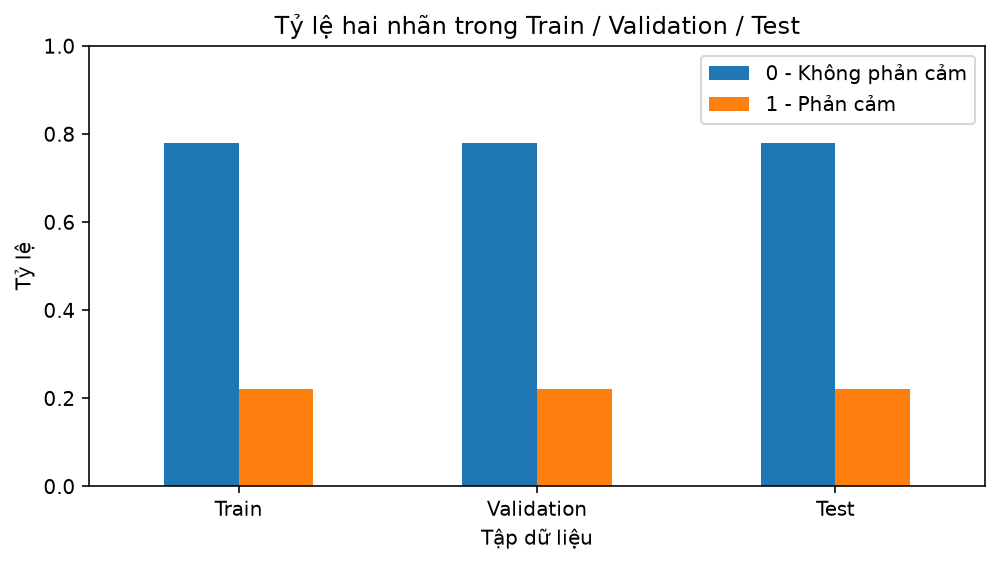

In [25]:
# CÂU 2: trực quan tỷ lệ nhãn trong từng tập sau chia phân tầng.
import matplotlib.pyplot as plt
split_plot = pd.DataFrame({
    'Train': train_df['label'].value_counts(normalize=True),
    'Validation': val_df['label'].value_counts(normalize=True),
    'Test': test_df['label'].value_counts(normalize=True),
}).fillna(0).T
ax = split_plot[[0, 1]].plot(kind='bar', figsize=(7, 4), rot=0)
ax.set(title='Tỷ lệ hai nhãn trong Train / Validation / Test', ylabel='Tỷ lệ', xlabel='Tập dữ liệu')
ax.legend(['0 - Không phản cảm', '1 - Phản cảm'])
ax.set_ylim(0, 1)
plt.tight_layout()

from io import BytesIO
_buf = BytesIO()
plt.savefig(_buf, format='png', dpi=145, bbox_inches='tight')
display(Image(data=_buf.getvalue()))
plt.close()

**2.3. Xử lý mất cân bằng:** Lớp 0 chiếm đa số; đồ án không tự nhân bản dữ liệu. Sử dụng `stratify` khi chia tập, chọn chỉ số F1/Recall/Precision của lớp 1 và so sánh hai mô hình trên cùng tập Test.

## CÂU 3 — SO SÁNH, TỐI ƯU VÀ CHẠY THỬ MÔ HÌNH (3,0 ĐIỂM)

So sánh **Multinomial Naive Bayes** và **LinearSVC** trên cùng dữ liệu; tối ưu C bằng 5-fold CV, chọn ngưỡng trên Validation, đánh giá Test độc lập.

In [26]:
# Hàm huấn luyện đối chứng Naive Bayes.
def fit_naive_bayes_baseline(train_df, val_df, test_df, max_features, min_df):
    """Fit a simple MultinomialNB baseline and tune its threshold on validation only."""
    model = make_pipeline(max_features, min_df, MultinomialNB(alpha=1.0))
    model.fit(train_df['text'], train_df['label'])
    classifier = model.named_steps['classifier']
    positive_index = list(classifier.classes_).index(1)
    val_scores = model.predict_proba(val_df['text'])[:, positive_index]
    threshold, validation_f1 = choose_threshold(val_scores, val_df['label'])
    test_scores = model.predict_proba(test_df['text'])[:, positive_index]
    test_predictions = (test_scores > threshold).astype(int)
    return model, threshold, validation_f1, test_scores, test_predictions


In [27]:
# Hàm 5-fold Cross-validation tìm C cho LinearSVC.
def tune_svm_c(train_df: pd.DataFrame, max_features: int, max_iter: int,
               tuning_fraction: float = 1.0, c_values=DEFAULT_C_VALUES):
    """Select C by average precision using stratified CV on train only.

    Full train subset is used by default; tuning_fraction<1 is only an
    explicit speed/diagnostic override and must not be used for reporting.
    """
    if not 0 < tuning_fraction <= 1:
        raise ValueError('tuning_fraction must be in (0, 1].')
    min_df = 2 if len(train_df) >= 100 else 1
    n_tune = min(len(train_df), max(100, int(round(len(train_df) * tuning_fraction))))
    if n_tune < len(train_df):
        tuning_df, _ = train_test_split(train_df, train_size=n_tune, random_state=SEED,
                                        stratify=train_df['label'])
    else:
        tuning_df = train_df.copy()
    min_class = int(tuning_df['label'].value_counts().min())
    n_splits = min(5, min_class)
    if n_splits < 2:
        raise ValueError('Not enough examples per class in the tuning subset for cross-validation.')
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    # Cache TF-IDF fit/transform for each CV fold so changing C does not
    # re-vectorize the same fold four times. The temporary cache is removed
    # automatically after model selection and is not part of the deliverable.
    with tempfile.TemporaryDirectory(prefix='textsense_cv_cache_') as cache_dir:
        memory = Memory(location=cache_dir, verbose=0)
        base = make_pipeline(max_features, min_df,
                             LinearSVC(max_iter=max_iter, random_state=SEED),
                             memory=memory)
        search = GridSearchCV(base, {'classifier__C': list(c_values)}, scoring='average_precision', cv=cv,
                              refit=True, n_jobs=1, return_train_score=False, error_score='raise')
        search.fit(tuning_df['text'], tuning_df['label'])
        # Detach the temporary cache reference before the directory is removed.
        best_c = float(search.best_params_['classifier__C'])
    table = pd.DataFrame({
        'C': [float(v) for v in search.cv_results_['param_classifier__C']],
        'mean_cv_average_precision': search.cv_results_['mean_test_score'].astype(float),
        'std_cv_average_precision': search.cv_results_['std_test_score'].astype(float),
        'rank': search.cv_results_['rank_test_score'].astype(int)
    }).sort_values(['rank', 'C']).reset_index(drop=True)
    return best_c, table, len(tuning_df), n_splits


**3.1. Tối ưu tham số C và huấn luyện LinearSVC**

In [28]:
# Chọn C bằng Cross Validation rồi fit LinearSVC trên toàn bộ Train.
min_df = 2 if len(train_df) >= 100 else 1
emit_progress(12, 'Đang chọn C bằng average precision, Stratified 5-fold CV trên toàn bộ train')
best_c, cv_table, tuning_rows, cv_splits = tune_svm_c(
    train_df, max_features, max_iter, tuning_fraction=tuning_fraction, c_values=c_values)
cv_table.to_csv(out / 'binary_cv_results.csv', index=False, encoding='utf-8-sig')
classifier = LinearSVC(C=best_c, max_iter=max_iter, random_state=SEED)

emit_progress(50, f'Đang fit TF-IDF + LinearSVC với C={best_c:g}')
pipeline = make_pipeline(max_features, min_df, classifier)
pipeline.fit(train_df['text'], train_df[ycol])

PROGRESS|12|Đang chọn C bằng average precision, Stratified 5-fold CV trên toàn bộ train
PROGRESS|50|Đang fit TF-IDF + LinearSVC với C=1


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",40000
,"dtype dtype: dtype, default=float64Type of the matrix returned by fit_transform() or transform().",<class 'numpy.float32'>
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True


In [29]:
# Xem kết quả Cross-validation từ biến hiện có.
display(cv_table if 'cv_table' in globals() else pd.read_csv(OUTPUT / 'binary_cv_results.csv'))

,C,mean_cv_average_precision,std_cv_average_precision,rank
0,1.0,0.928408,0.003055,1
1,2.0,0.927441,0.003140,2
2,0.5,0.924146,0.003066,3
3,5.0,0.920359,0.003568,4


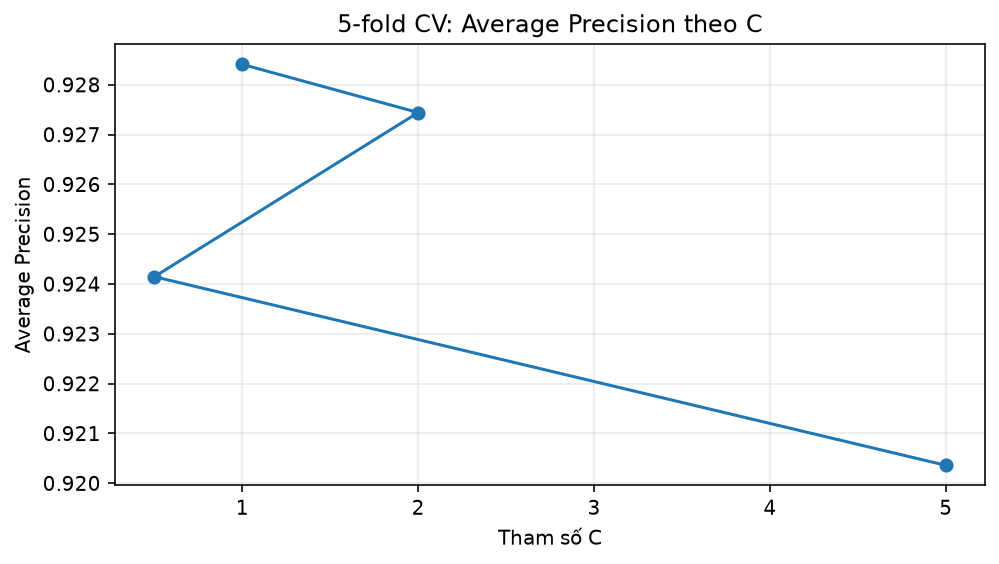

In [30]:
# CÂU 3: biểu đồ mức điểm Average Precision của từng giá trị C.
import matplotlib.pyplot as plt
cv_plot = cv_table.copy()
if 'param_classifier__C' in cv_plot.columns:
    c_axis = cv_plot['param_classifier__C'].astype(float)
elif 'param_model__C' in cv_plot.columns:
    c_axis = cv_plot['param_model__C'].astype(float)
elif 'C' in cv_plot.columns:
    c_axis = cv_plot['C'].astype(float)
else:
    c_axis = None
score_col = next((k for k in ['mean_cv_average_precision', 'mean_test_score', 'mean_average_precision', 'mean_AP'] if k in cv_plot.columns), None)
if c_axis is not None and score_col is not None:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(c_axis, cv_plot[score_col], marker='o')
    ax.set(title='5-fold CV: Average Precision theo C', xlabel='Tham số C', ylabel='Average Precision')
    ax.grid(alpha=.25)
    plt.tight_layout(); 
    from io import BytesIO
    _buf = BytesIO()
    plt.savefig(_buf, format='png', dpi=145, bbox_inches='tight')
    display(Image(data=_buf.getvalue()))
    plt.close()
else:
    print('Xem bảng CV phía trên để đối chiếu các giá trị C.')

**3.2. Chọn ngưỡng phân loại trên Validation**

In [31]:
# Tính decision score, tìm ngưỡng từ Validation và dự đoán Test.
emit_progress(72, 'Đang chọn ngưỡng quyết định chỉ từ validation')
svm_val_scores = pipeline.decision_function(val_df['text'])
threshold, validation_f1 = choose_threshold(svm_val_scores, val_df[ycol])
svm_val_predictions = (svm_val_scores > threshold).astype(int)
svm_validation_metrics = binary_scores(val_df[ycol], svm_val_predictions)
test_scores = pipeline.decision_function(test_df['text'])
baseline_threshold_predictions = (test_scores > 0.0).astype(int)
predictions = (test_scores > threshold).astype(int)


PROGRESS|72|Đang chọn ngưỡng quyết định chỉ từ validation


**3.3. Huấn luyện Naive Bayes và so sánh công bằng**

In [32]:
# Xuất bảng binary_model_comparison.csv với Accuracy/Precision/Recall/F1.
emit_progress(76, 'Đang huấn luyện baseline Naive Bayes trên cùng tập dữ liệu')
nb_model, nb_threshold, nb_validation_f1, nb_test_scores, nb_predictions = fit_naive_bayes_baseline(
    train_df, val_df, test_df, max_features, min_df)
nb_test_metrics = binary_scores(test_df[ycol], nb_predictions)
svm_test_metrics = binary_scores(test_df[ycol], predictions)
nb_positive_index = list(nb_model.named_steps['classifier'].classes_).index(1)
nb_val_scores = nb_model.predict_proba(val_df['text'])[:, nb_positive_index]
nb_val_predictions = (nb_val_scores > nb_threshold).astype(int)
nb_validation_metrics = binary_scores(val_df[ycol], nb_val_predictions)
comparison_rows = []
for model_name, model_threshold, val_metrics, test_metrics in [
    ('MultinomialNB + TF-IDF (baseline)', nb_threshold, nb_validation_metrics, nb_test_metrics),
    ('LinearSVC + TF-IDF (mô hình chính)', threshold, svm_validation_metrics, svm_test_metrics)
]:
    comparison_rows.append({
        'model': model_name, 'threshold': float(model_threshold),
        **{f'validation_{key}': value for key, value in val_metrics.items() if key != 'confusion_matrix_labels_0_1'},
        **{f'test_{key}': value for key, value in test_metrics.items() if key != 'confusion_matrix_labels_0_1'}
    })
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(out / 'binary_model_comparison.csv', index=False, encoding='utf-8-sig')

PROGRESS|76|Đang huấn luyện baseline Naive Bayes trên cùng tập dữ liệu


In [33]:
# Bảng so sánh hai mô hình; biến comparison được tạo ở cell ngay phía trên.
# Chạy notebook tuần tự từ trên xuống để bảo đảm đã huấn luyện xong hai mô hình.
display(comparison)

,model,threshold,validation_samples,validation_accuracy,validation_precision_1,validation_recall_1,validation_f1_1,test_samples,test_accuracy,test_precision_1,test_recall_1,test_f1_1
0,MultinomialNB + TF-IDF (baseline),0.264283,23527,0.852127,0.655615,0.691194,0.672934,39212,0.850836,0.649597,0.699652,0.673696
1,LinearSVC + TF-IDF (mô hình chính),-0.220318,23527,0.945679,0.863535,0.894554,0.878771,39212,0.945476,0.859867,0.898725,0.878867


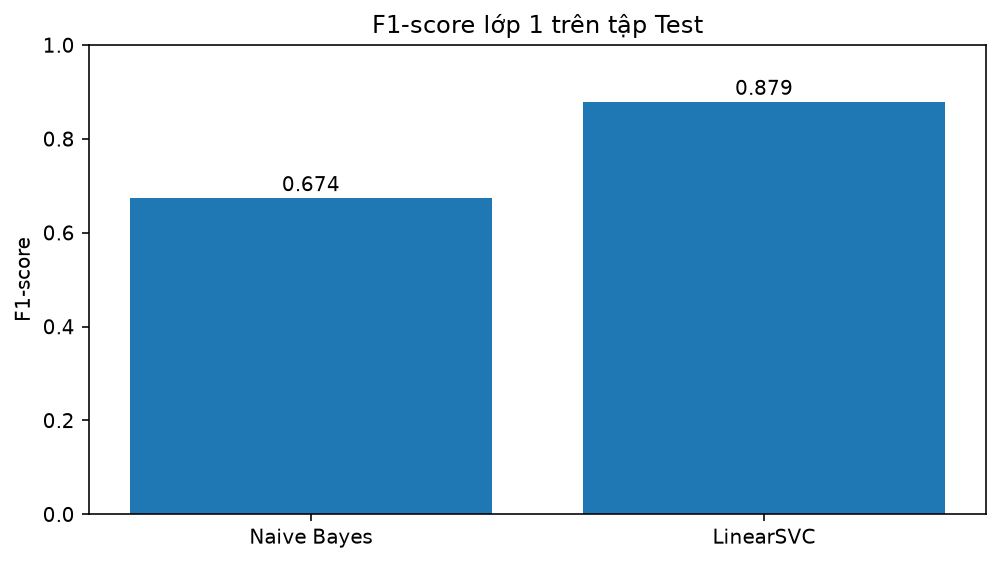

In [34]:
# CÂU 3: đối chiếu F1 lớp 1 trên Test giữa hai mô hình.
import matplotlib.pyplot as plt
comparison_plot = pd.read_csv(OUTPUT / 'binary_model_comparison.csv')
if 'test_f1_1' in comparison_plot.columns:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(['Naive Bayes', 'LinearSVC'], comparison_plot['test_f1_1'].to_numpy())
    ax.set(title='F1-score lớp 1 trên tập Test', ylabel='F1-score', ylim=(0, 1))
    for i, v in enumerate(comparison_plot['test_f1_1']): ax.text(i, v + 0.015, f'{v:.3f}', ha='center')
    plt.tight_layout(); 
    from io import BytesIO
    _buf = BytesIO()
    plt.savefig(_buf, format='png', dpi=145, bbox_inches='tight')
    display(Image(data=_buf.getvalue()))
    plt.close()

In [35]:
# Hàm tạo ma trận nhầm lẫn, PR Curve và phân tích lỗi.
def save_binary_diagnostics(out: Path, test_df: pd.DataFrame, y_true, y_pred, scores,
                            threshold: float, pipeline: Pipeline, mapping: dict) -> dict:
    """Write PR curve, misclassification analysis and linear SVM token coefficients."""
    out.mkdir(parents=True, exist_ok=True)
    precision, recall, thresholds = precision_recall_curve(y_true, scores, pos_label=1)
    pr_frame = pd.DataFrame({
        'recall': recall, 'precision': precision,
        'threshold': np.r_[thresholds, np.nan]
    })
    pr_path = out / 'binary_pr_curve.csv'
    pr_frame.to_csv(pr_path, index=False, encoding='utf-8-sig')

    try:
        import matplotlib
        matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(7.2, 5.2))
        ap_value = average_precision_score(y_true, scores)
        ax.plot(recall, precision, label=f'LinearSVC (AP={ap_value:.3f})')
        ax.set(xlabel='Recall lớp 1 (Phản cảm)', ylabel='Precision lớp 1 (Phản cảm)',
               title='Precision–Recall curve trên tập test')
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.grid(True, alpha=0.25)
        ax.legend(loc='best')
        fig.tight_layout()
        fig.savefig(out / 'binary_pr_curve.png', dpi=160)
        plt.close(fig)

        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        fig, ax = plt.subplots(figsize=(5.8, 5.0))
        image = ax.imshow(cm, cmap='Blues')
        ax.set(xticks=[0, 1], yticks=[0, 1],
               xticklabels=['0 - Không phản cảm', '1 - Phản cảm'],
               yticklabels=['0 - Không phản cảm', '1 - Phản cảm'],
               xlabel='Nhãn dự đoán', ylabel='Nhãn thực tế',
               title='Confusion Matrix trên tập test')
        for (i, j), value in np.ndenumerate(cm):
            ax.text(j, i, f'{value:,}', ha='center', va='center', color='black')
        fig.colorbar(image, ax=ax, fraction=.046, pad=.04)
        fig.tight_layout(); fig.savefig(out / 'binary_confusion_matrix.png', dpi=160); plt.close(fig)
    except ImportError:  # pragma: no cover - matplotlib is a declared dependency
        pass

    errors = test_df[['source', 'text', 'category']].copy()
    errors['true_label'] = np.asarray(y_true, dtype=int)
    errors['true_name'] = [mapping[int(v)] for v in errors['true_label']]
    errors['predicted_label'] = np.asarray(y_pred, dtype=int)
    errors['predicted_name'] = [mapping[int(v)] for v in errors['predicted_label']]
    errors['decision_score'] = np.asarray(scores, dtype=float)
    errors['decision_threshold'] = float(threshold)
    errors['error_type'] = np.select(
        [(errors.true_label == 1) & (errors.predicted_label == 0),
         (errors.true_label == 0) & (errors.predicted_label == 1)],
        ['false_negative', 'false_positive'], default='correct')
    errors['error_severity'] = np.where(
        errors.error_type.eq('false_negative'), threshold - errors.decision_score,
        np.where(errors.error_type.eq('false_positive'), errors.decision_score - threshold, 0.0))
    errors = errors.loc[errors.error_type.ne('correct')].sort_values(
        'error_severity', ascending=False).reset_index(drop=True)
    errors.to_csv(out / 'binary_error_analysis.csv', index=False, encoding='utf-8-sig')

    vectorizer = pipeline.named_steps['tfidf']
    classifier = pipeline.named_steps['classifier']
    feature_names = vectorizer.get_feature_names_out()
    coefficients = np.asarray(classifier.coef_).reshape(-1)
    top_n = min(100, len(coefficients))
    positive_idx = np.argsort(coefficients)[-top_n:][::-1]
    negative_idx = np.argsort(coefficients)[:top_n]
    feature_rows = []
    for direction, indexes in [('Ủng hộ lớp 1 - Phản cảm (proxy)', positive_idx),
                               ('Ủng hộ lớp 0 - Không phản cảm (proxy)', negative_idx)]:
        for rank, index in enumerate(indexes, start=1):
            feature_rows.append({'direction': direction, 'rank': rank,
                                 'feature': str(feature_names[index]),
                                 'coefficient': float(coefficients[index])})
    pd.DataFrame(feature_rows).to_csv(out / 'binary_feature_importance.csv', index=False, encoding='utf-8-sig')
    false_negative = int(errors.error_type.eq('false_negative').sum())
    false_positive = int(errors.error_type.eq('false_positive').sum())
    return {
        'test_average_precision': float(average_precision_score(y_true, scores)),
        'pr_curve_csv': pr_path.name, 'pr_curve_png': 'binary_pr_curve.png',
        'misclassified_rows': int(len(errors)), 'false_negative_rows': false_negative,
        'false_positive_rows': false_positive,
        'error_analysis_csv': 'binary_error_analysis.csv',
        'feature_importance_csv': 'binary_feature_importance.csv',
        'feature_importance_note': 'LinearSVC coefficients describe association in this fitted TF-IDF model, not causal explanations.'
    }


**3.4. Đánh giá mô hình trên tập Test**

In [36]:
# Ghi Accuracy, F1, ma trận nhầm lẫn, nguồn dữ liệu và cấu hình huấn luyện.
emit_progress(80, 'Đang đánh giá test và chạy bootstrap')
labels_present = sorted(mapping)
report = classification_report(
    test_df[ycol], predictions, labels=labels_present,
    target_names=[mapping[x] for x in labels_present],
    zero_division=0, output_dict=True)
metrics = {
    'task': 'binary', 'model': 'TF-IDF + LinearSVC',
    'train_rows': int(len(train_df)), 'validation_rows': int(len(val_df)),
    'test_rows': int(len(test_df)), 'accuracy': float(accuracy_score(test_df[ycol], predictions)),
    'f1_macro': float(f1_score(test_df[ycol], predictions, average='macro', zero_division=0)),
    'classification_report': report,
    'confusion_matrix': confusion_matrix(test_df[ycol], predictions, labels=labels_present).tolist(),
    'classes': labels_present, 'class_names': {str(k): v for k, v in mapping.items()},
    'source_stats': stats, 'descriptive_stats': descriptive_stats, 'random_seed': SEED, 'sklearn_version': sklearn.__version__,
    'class_distribution_by_split': {
        name: {str(int(k)): int(v) for k, v in part['label'].value_counts().sort_index().items()}
        for name, part in [('train', train_df), ('validation', val_df), ('test', test_df)]
    },
    'baseline_comparison': {
        'baseline': 'MultinomialNB + TF-IDF', 'threshold': float(nb_threshold),
        'validation': nb_validation_metrics, 'test': nb_test_metrics,
        'comparison_file': 'binary_model_comparison.csv',
        'note': 'Baseline được fit trên cùng tập train, cùng dữ liệu và cùng split; ngưỡng được chọn trên validation, không dùng test để điều chỉnh.'
    },
    'data_provenance': {
        'dataset': 'Twitter and Reddit Sentimental Analysis Dataset',
        'creator': 'cosmos98 (Kaggle)', 'url': DATASET_URL, 'license': DATASET_LICENSE,
        'files_used': ['Twitter_Data.csv', 'Reddit_Data.csv'],
        'labeling_method': 'Bộ dữ liệu cung cấp nhãn cảm xúc; thuật toán gán nhãn gốc không được mô tả đủ để tái lập.'
    },
    'preprocessing': {
        'version': 'textsense_clean_v2', 'same_for_train_and_inference': True,
        'steps': ['NFKC Unicode', 'remove leading RT @handle prefix', 'remove URLs',
                  'casefold', 'remove punctuation', 'collapse whitespace']
    },
    'python_version': platform.python_version(),
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'split_protocol': {
        'train_validation_test': [round(0.80 * (1 - validation_size), 6),
                                  round(0.80 * validation_size, 6), 0.20],
        'validation_size_within_train_val': validation_size, 'seed': SEED,
        'token_normalized_deduplication': True, 'retweet_prefix_normalization': True,
        'fuzzy_minhash_deduplication': False, 'assert_no_token_overlap': True
    },
    'data_hashes': {
        'canonical_dataset_sha256': stats.get('canonical_dataset_sha256'),
        'source_file_sha256': stats.get('source_file_sha256', {})
    },
    'split_file_sha256': split_hashes,
    'tuning': {
        'method': 'StratifiedKFold', 'folds': cv_splits, 'tuning_rows': int(tuning_rows),
        'requested_tuning_fraction': tuning_fraction,
        'actual_tuning_fraction': float(tuning_rows / len(train_df)),
        'c_values': list(c_values), 'selected_C': best_c,
        'selection_metric': 'average_precision (AP, class 1) trên decision_function của CV; không dùng test để chọn tham số'
    },
    'note': ('Quy ước nhãn proxy của đồ án: category -1 (Tiêu cực) → 1 (Phản cảm); '
             'category 0 (Trung tính) và category 1 (Tích cực) → 0 (Không phản cảm). '
             'Đây là quy ước ánh xạ từ nhãn cảm xúc, không phải nhãn phản cảm được xác minh độc lập.')
}

PROGRESS|80|Đang đánh giá test và chạy bootstrap


**3.5. Bootstrap, kiểm tra lỗi dự đoán và tạo biểu đồ**

In [37]:
# Tính bootstrap, phân tích lỗi và thống kê kết quả theo từng nguồn.
metrics['decision'] = {
    'default_threshold': 0.0, 'validation_selected_threshold': float(threshold),
    'validation_f1_selected': float(validation_f1),
    'test_threshold_0': binary_scores(test_df[ycol], baseline_threshold_predictions),
    'test_threshold_selected': binary_scores(test_df[ycol], predictions)
}
metrics['test_bootstrap_95pct_f1_1'] = bootstrap_f1_ci(
    test_df[ycol], predictions, bootstrap_samples, SEED)
emit_progress(84, 'Đang tạo PR curve và phân tích lỗi')
metrics['diagnostics'] = save_binary_diagnostics(
    out, test_df, test_df[ycol].to_numpy(), predictions, test_scores, threshold, pipeline, mapping)
metrics['by_source'] = {}
for source in sorted(test_df['source'].astype(str).unique()):
    mask = test_df['source'].astype(str).to_numpy() == source
    metrics['by_source'][source] = binary_scores(test_df.loc[mask, ycol], predictions[mask])
word_counts = test_df['text'].str.split().str.len()
bins = pd.cut(word_counts, bins=[-1, 8, 20, float('inf')], labels=['<=8', '9-20', '>=21'])
metrics['by_length'] = {}
for length_group in bins.cat.categories:
    mask = (bins == length_group).to_numpy()
    if mask.sum():
        metrics['by_length'][str(length_group)] = binary_scores(
            test_df.loc[mask, ycol], predictions[mask])
metrics['length_analysis_note'] = (
    'Hiệu năng có thể giảm ở văn bản dài; cần đọc chỉ số by_length trên test, '
    'không suy rộng thành quy luật phổ quát.')
metrics['by_original_sentiment'] = {}
for category in sorted(test_df['category'].unique()):
    mask = test_df['category'].to_numpy() == category
    metrics['by_original_sentiment'][str(int(category))] = {
        'samples': int(mask.sum()),
        'positive_prediction_rate': float(np.mean(predictions[mask]))
    }
metrics['cv_results'] = cv_table.to_dict(orient='records')

PROGRESS|84|Đang tạo PR curve và phân tích lỗi


KẾT QUẢ ĐÁNH GIÁ TEST (LINEARSVC):


,Giá trị
samples,39212
accuracy,0.945476
precision_1,0.859867
recall_1,0.898725
f1_1,0.878867
confusion_matrix_labels_0_1,"[[29318, 1264], [874, 7756]]"


BIỂU ĐỒ: Confusion Matrix


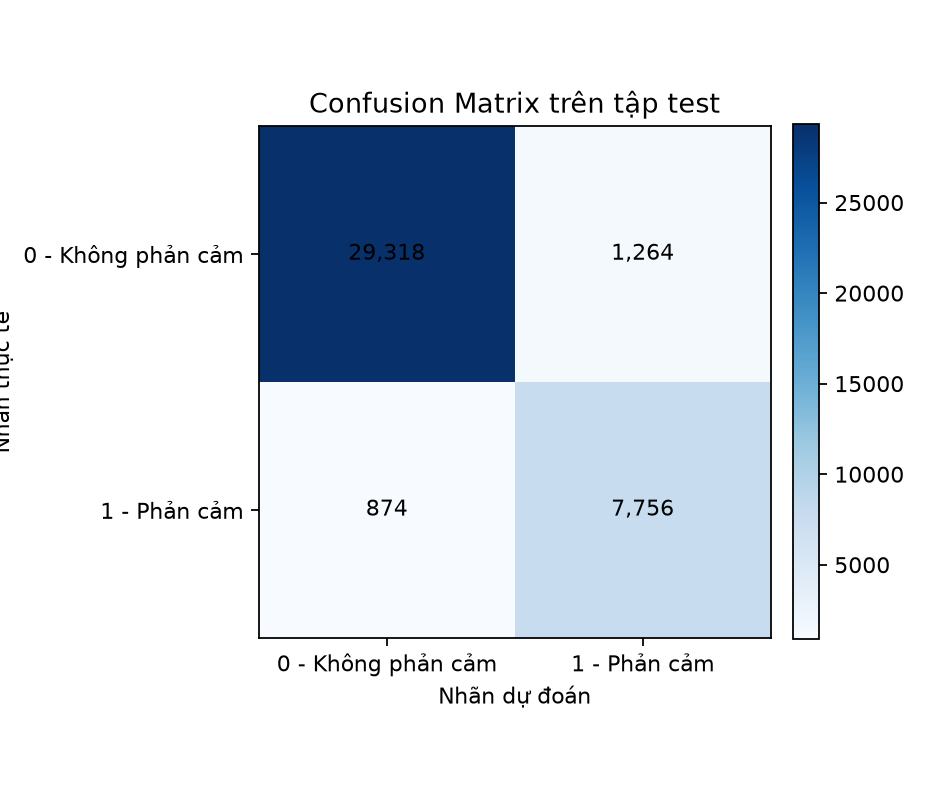

BIỂU ĐỒ: Precision–Recall Curve


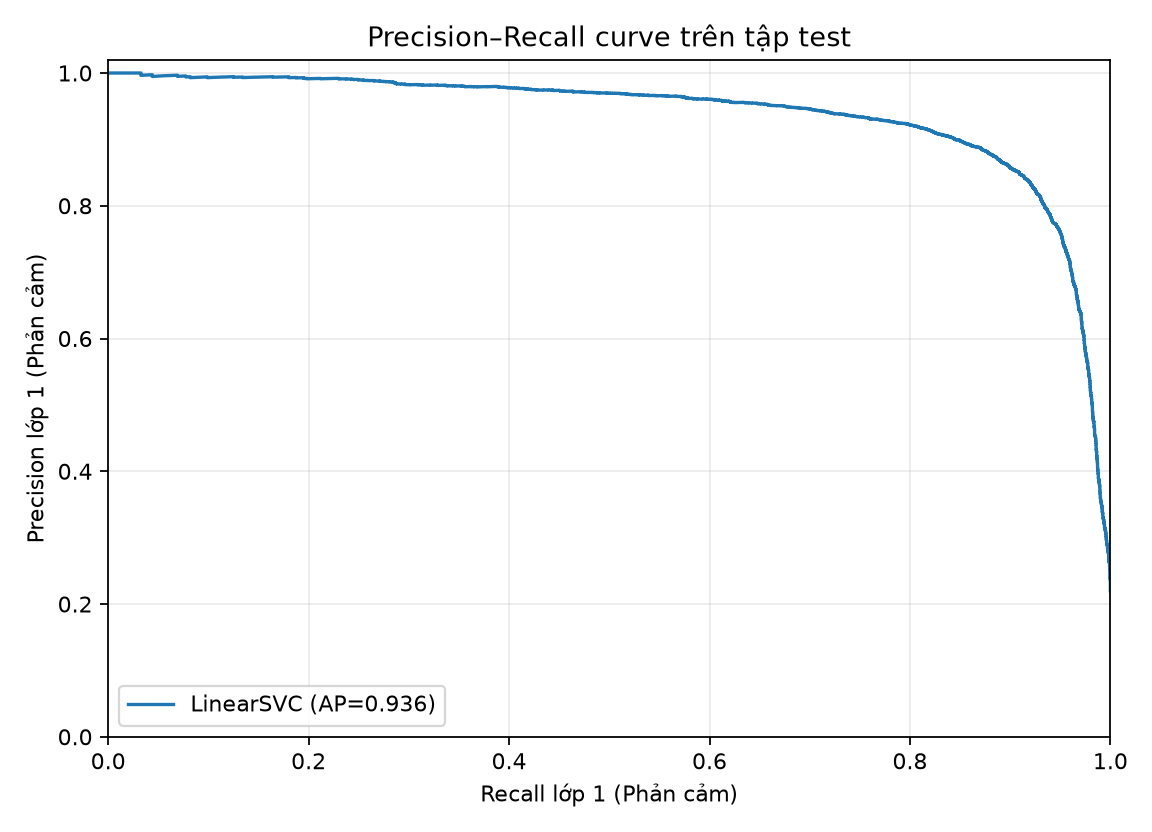

In [38]:
# Hiển thị trực tiếp hai biểu đồ đánh giá ngay dưới cell.
print('KẾT QUẢ ĐÁNH GIÁ TEST (LINEARSVC):')
display(pd.DataFrame([metrics['decision']['test_threshold_selected']]).T.rename(columns={0:'Giá trị'}))
for title, name in [('Confusion Matrix', 'binary_confusion_matrix.png'),
                    ('Precision–Recall Curve', 'binary_pr_curve.png')]:
    print('BIỂU ĐỒ:', title)
    display(Image(filename=str(OUTPUT / name)))

**3.6. Lưu mô hình và các file kết quả thực nghiệm**

In [39]:
# Lưu model, metrics JSON, bảng dự đoán test, manifest.
artifact = {
    'pipeline': pipeline, 'task': 'binary', 'class_names': mapping,
    'threshold': float(threshold), 'sklearn_version': sklearn.__version__,
    'created_utc': metrics['created_utc'], 'python_version': platform.python_version(),
    'data_sha256': stats.get('canonical_dataset_sha256'), 'selected_C': float(best_c)
}
out.mkdir(parents=True, exist_ok=True)
model_path = out / 'binary_linear_svm.joblib'
joblib.dump(artifact, model_path, compress=3)
metrics_path = out / 'binary_metrics.json'
metrics_path.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')

result = test_df[[c for c in ('source', 'text', 'category') if c in test_df]].copy()
result['truth'] = test_df[ycol].to_numpy()
result['truth_name'] = [mapping[int(v)] for v in result['truth']]
result['prediction'] = predictions
result['prediction_name'] = [mapping[int(v)] for v in predictions]
result['prediction_threshold_0'] = baseline_threshold_predictions
result['decision_score'] = test_scores
result.to_csv(out / 'binary_test_predictions.csv', index=False, encoding='utf-8-sig')

manifest = {
    'task': 'binary', 'created_utc': metrics['created_utc'], 'seed': SEED,
    'data_hashes': metrics['data_hashes'], 'split_file_sha256': split_hashes,
    'split_rows': {'train': len(train_df), 'validation': len(val_df), 'test': len(test_df)},
    'model_file_sha256': sha256_file(model_path), 'metrics_file_sha256': sha256_file(metrics_path)
}
(out / 'binary_manifest.json').write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')

980

In [40]:
# Liệt kê minh chứng được tạo (không tự sinh báo cáo Markdown).
print('Model:',model_path)
for name in ['binary_metrics.json','binary_model_comparison.csv','binary_cv_results.csv', 'binary_test_predictions.csv','binary_confusion_matrix.png','binary_pr_curve.png']:
    print(('OK' if (OUTPUT/name).is_file() else 'THIẾU'), name)

Model: C:\Users\vothi\OneDrive\Desktop\TextSense\01_TRAIN_MODEL\outputs\binary_linear_svm.joblib
OK binary_metrics.json
OK binary_model_comparison.csv
OK binary_cv_results.csv
OK binary_test_predictions.csv
OK binary_confusion_matrix.png
OK binary_pr_curve.png


**3.7. Dự đoán thử một vài câu mới**

In [41]:
# Nạp file .joblib và dự đoán hai câu tiếng Anh để trình diễn.
import joblib
model_file = OUTPUT / 'binary_linear_svm.joblib'
if model_file.exists():
    artifact = joblib.load(model_file)
    examples = ['I love this wonderful day', 'I absolutely hate this terrible experience']
    cleaned_examples = [normalize_text(t) for t in examples]
    scores = artifact['pipeline'].decision_function(cleaned_examples)
    predictions = (scores > artifact['threshold']).astype(int)
    display(pd.DataFrame({'text':examples,'label':predictions,
                          'name':[BINARY_NAMES[int(v)] for v in predictions], 'score':scores}))
else:
    print('Chưa có model; cần chạy cell huấn luyện trước.')

,text,label,name,score
0,I love this wonderful day,0,Không phản cảm,-4.257861
1,I absolutely hate this terrible experience,1,Phản cảm,5.889657


## CÂU 4 — THIẾT KẾ ỨNG DỤNG VÀ TRÌNH BÀY (2,0 ĐIỂM)

Giao diện nằm trong thư mục `03_GIAO_DIEN`. Notebook chỉ kiểm tra model và kết quả để ứng dụng sử dụng; không trộn code giao diện vào phần huấn luyện.

**4.1. Kiểm tra file mô hình và các hình minh chứng**

In [42]:
# Kiểm tra model và minh chứng thực nghiệm phục vụ giao diện/bảo vệ.
required_files = [
    'binary_linear_svm.joblib', 'binary_metrics.json',
    'binary_model_comparison.csv', 'binary_cv_results.csv',
    'binary_confusion_matrix.png', 'binary_pr_curve.png',
]
for name in required_files:
    file_path = OUTPUT / name
    print(('OK' if file_path.is_file() else 'THIẾU'), name)


OK binary_linear_svm.joblib
OK binary_metrics.json
OK binary_model_comparison.csv
OK binary_cv_results.csv
OK binary_confusion_matrix.png
OK binary_pr_curve.png


**4.2. Chạy giao diện từ Terminal VS Code**

```powershell
py -3 -m pip install -r 03_GIAO_DIEN/requirements.txt
cd 03_GIAO_DIEN
py -3 serve_textsense.py
```

Truy cập `http://127.0.0.1:8502`. Trình diễn dự đoán câu đơn và tải CSV. Đưa ảnh chụp màn hình vào **báo cáo Word riêng**; không cần cell tạo báo cáo Markdown trong Câu 3.